In [1]:
# Imports and environment first, all in one place

from dotenv import load_dotenv
from IPython.display import Image, display
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.middleware import wrap_tool_call
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_groq import ChatGroq
load_dotenv(override=True)

True

In [2]:
llm=ChatGroq(model="openai/gpt-oss-120b")

In [3]:
agent = create_agent(
   llm,
    system_prompt="You are a helpful assistant who answers concisely.",
)

result = agent.invoke({"messages": [{"role": "user", "content": "What is the Model Context Protocol, in two sentences?"}]})
print(result["messages"][-1].content)

The Model Context Protocol (MCP) is a structured framework for managing and transmitting the relevant conversational or task‑specific information that an AI model needs to maintain coherence across interactions, typically by defining how context is captured, formatted, and updated. It ensures that the model can reliably reference prior inputs, system instructions, and metadata without exceeding its context window limits.


In [4]:
result = await agent.ainvoke({"messages": [{"role": "user", "content": "In one sentence: why does async code suit agents so well?"}]})
print(result["messages"][-1].content)

Because async code lets agents handle many I/O‑bound or time‑delayed actions concurrently without blocking, enabling them to stay responsive, scale efficiently, and coordinate multiple tasks or external services in real time.


In [5]:
@tool
def get_weather(city: str) -> str:
    """Return today's weather for a city."""
    pretend = {"London": "rainy, 14 degrees", "Rome": "sunny, 27 degrees"}
    return pretend.get(city, "clear, 20 degrees")

@tool
def get_population(city: str) -> str:
    """Return the population of a city."""
    pretend = {"London": "8.9 million", "Rome": "2.8 million"}
    return pretend.get(city, "unknown")

agent = create_agent(
   llm,
    tools=[get_weather, get_population],
    system_prompt="You are a travel assistant. Use your tools to answer questions about cities.",
)

result = agent.invoke({"messages": [{"role": "user", "content": "What is the weather and population of Rome?"}]})
print(result["messages"][-1].content)

**Rome, Italy**

- **Current Weather:** Sunny, 27 °C (about 81 °F)  
- **Population:** Approximately **2.8 million** residents  

Enjoy your day in the Eternal City! Let me know if you need more details about attractions, travel tips, or anything else.


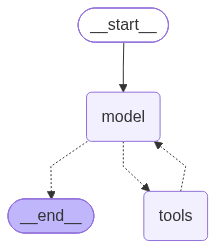

In [6]:
display(Image(agent.get_graph().draw_mermaid_png()))

In [7]:
memory_agent = create_agent(
    llm,
    tools=[get_weather],
    checkpointer=MemorySaver(),
)

config = {"configurable": {"thread_id": "trip-planning"}}
memory_agent.invoke({"messages": [{"role": "user", "content": "I am planning a trip to London."}]}, config=config)
result = memory_agent.invoke({"messages": [{"role": "user", "content": "What is the weather like where I am going on my trip?"}]}, config=config)
print(result["messages"][-1].content)

The current weather in London is **rainy with a temperature around 14 °C (57 °F)**. Expect light‑to‑moderate showers and cool, mild conditions—perfect for a waterproof jacket, an umbrella, and layered clothing. If you’d like a short‑term forecast (e.g., the next 24‑48 hours) or any tips on dressing for the weather, just let me know!


In [ ]:
from langchain.agents.structured_output import ToolStrategy

class CityReport(BaseModel):
    city: str = Field(description="The city name")
    weather: str = Field(description="A short weather description")
    population: str = Field(description="The population")

report_agent = create_agent(
    llm,
    tools=[get_weather, get_population],
    response_format=ToolStrategy(CityReport),
)

result = report_agent.invoke({"messages": [{"role": "user", "content": "Give me a report on London."}]})
report = result["structured_response"]
print(report)
print("Just the weather:", report.weather)

city='London' weather='rainy, 14°C' population='8.9 million'
Just the weather: rainy, 14°C


In [9]:
@wrap_tool_call
def log_tool_calls(request, handler):
    call = request.tool_call
    print(f"  [middleware] calling {call['name']} with {call['args']}")
    return handler(request)

watched_agent = create_agent(
   llm,
    tools=[get_weather, get_population],
    system_prompt="You are a travel assistant. Use your tools.",
    middleware=[log_tool_calls],
)

result = watched_agent.invoke({"messages": [{"role": "user", "content": "Weather and population of London and Rome?"}]})
print("\nFinal answer:", result["messages"][-1].content)

  [middleware] calling get_weather with {'city': 'London'}
  [middleware] calling get_weather with {'city': 'Rome'}
  [middleware] calling get_population with {'city': 'London'}
  [middleware] calling get_population with {'city': 'Rome'}

Final answer: **Weather (today)**  
- **London:** Rainy, 14 °C  
- **Rome:** Sunny, 27 °C  

**Population (latest available)**  
- **London:** ~8.9 million people  
- **Rome:** ~2.8 million people


## Before Part 6: Node and Playwright

The last part of this lab uses tools that live in a separate program, an MCP server, and that program runs on Node. Two quick checks before we start.

First, Node itself; you want v22 or later. If the cell below fails, install Node with one command:

- **Windows**, in PowerShell: `winget install OpenJS.NodeJS.LTS`
- **Mac**, in Terminal: `brew install node`
- **Linux**, or if neither works for you: see the guide at [setup/SETUP-node.md](../setup/SETUP-node.md)

After installing, quit Cursor completely and start it again, then reopen this notebook and re-run the lab from the top. That full restart matters: a freshly installed Node is invisible to a notebook that was already running, and restarting just the kernel is not enough.

In [10]:
!node --version
!npx --version

v22.23.1
10.9.8


Second, Playwright, Microsoft's browser automation framework. There is nothing to install: `npx` fetches it on demand, and it drives the copy of Chrome already on your machine. Chrome does not need to be running; Playwright launches its own.

The cell below proves the whole chain with no AI involved at all: Node runs Playwright, Playwright opens Chrome, loads Hacker News, and saves a screenshot. The first run takes a little longer while npx downloads the package.

If it complains that Chrome is not found, either install Chrome normally or run `npx playwright install chrome` in a terminal, then try again.

\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|/-\|Navigating to https://news.ycombinator.com
Capturing screenshot into playwright_check.png
\

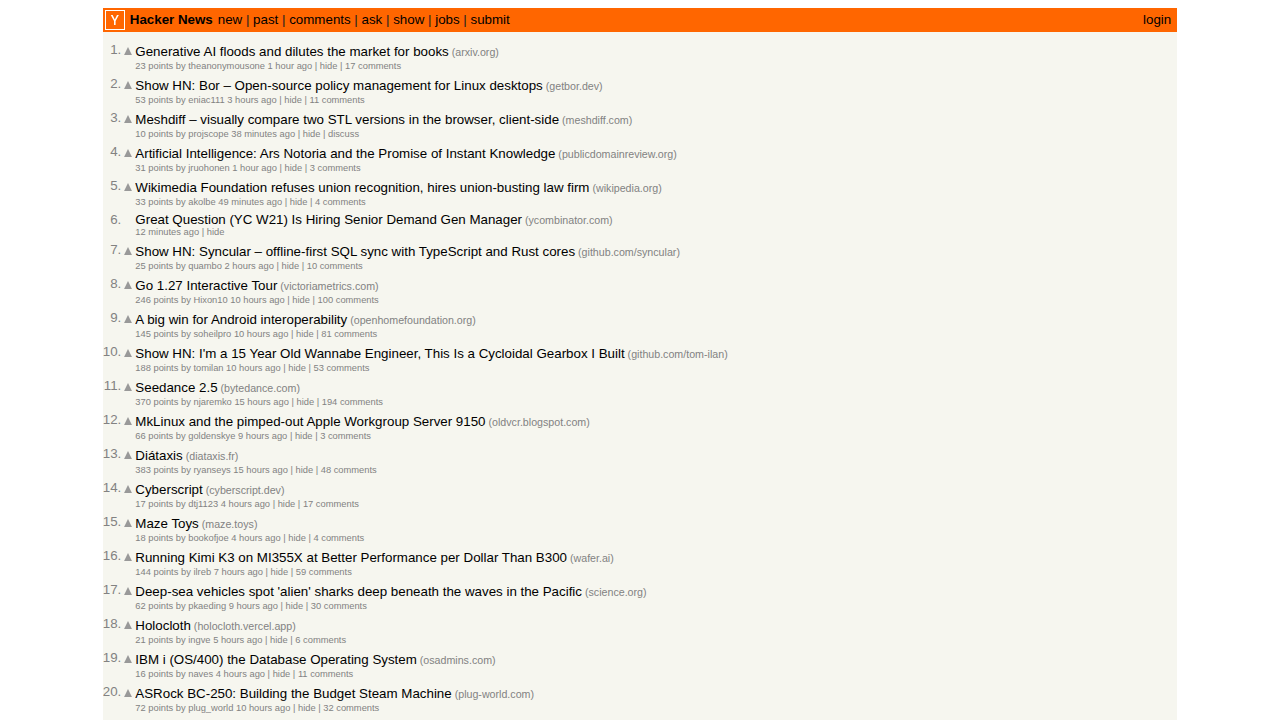

In [11]:
!npx -y playwright@latest screenshot --channel=chrome https://news.ycombinator.com playwright_check.png
display(Image("playwright_check.png"))

## Part 6: an MCP server, and a real browser

Tools do not have to be Python functions you write. The Model Context Protocol is a standard way for agents to use tools that live in a separate server. LangChain loads those tools with `langchain-mcp-adapters`, and from the agent's point of view they are just tools like any other.

We will connect to Microsoft's Playwright MCP server, which drives the same real browser you just smoke-tested. It runs headed by default, so you can watch it work; on a Linux box with no display it quietly falls back to headless. Because these tools talk to a separate process, they are async, so we load them with `await` and run the agent with `ainvoke`, which you met in Part 1.

### One adjustment for Windows

When Python launches another program, it hands that program a place to write its error messages. Inside a Jupyter notebook on Windows, that place is not a real file, and the library that launches MCP servers trips over it (a known issue in the MCP Python SDK, which only shows up in notebooks, never in ordinary Python scripts). The cell below points the MCP server's error log somewhere safe before we connect. On Mac and Linux it does nothing at all, so run it either way and carry on.

In [12]:
import sys

if sys.platform == "win32":
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, errlog=subprocess.DEVNULL)
    print("Applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

Not Windows, so nothing to do here


In [13]:
client = MultiServerMCPClient({
    "playwright": {
        "transport": "stdio",
        "command": "npx",
        "args": ["-y", "@playwright/mcp@latest", "--isolated"],
    }
})

browser_tools = await client.get_tools()
print(f"Loaded {len(browser_tools)} browser tools:")
for t in browser_tools:
    print(" -", t.name)

Loaded 24 browser tools:
 - browser_close
 - browser_resize
 - browser_console_messages
 - browser_handle_dialog
 - browser_evaluate
 - browser_file_upload
 - browser_drop
 - browser_find
 - browser_fill_form
 - browser_press_key
 - browser_type
 - browser_navigate
 - browser_navigate_back
 - browser_network_requests
 - browser_network_request
 - browser_run_code_unsafe
 - browser_take_screenshot
 - browser_snapshot
 - browser_click
 - browser_drag
 - browser_hover
 - browser_select_option
 - browser_tabs
 - browser_wait_for


Now we hand those browser tools to an ordinary `create_agent` and ask it to visit Hacker News and report what it finds. Watch the browser window open and navigate on its own.

In [ ]:
browser_agent = create_agent(
         llm,
    tools=browser_tools,
    system_prompt="You are a web research assistant. Use the browser tools to complete the task, then report clearly.",
)

result = await browser_agent.ainvoke({"messages": [{"role": "user",
    "content": "Go to https://news.ycombinator.com and tell me the titles of the top three stories on the front page."}]})
print(result["messages"][-1].content)

## Recap, and where we are heading

In one lab you have built an agent in a single line, seen that it is really a LangGraph graph, given it tools, memory and structured output, shaped it with middleware, and let it drive a real browser through an MCP server. This is the layer you will reach for most often in your own work.

Tomorrow we go one layer higher. Deep Agents take create_agent and wrap it in a full harness for work that takes many steps.

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/exercise.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#ff7800;">Exercise</h2>
            <span style="color:#ff7800;">Give the browser agent a checkpointer and a thread_id, then hold a short back and forth with it: ask it to open a site, then ask a follow up question about what it found, and confirm it remembers. For a bigger challenge, write a piece of middleware that refuses any navigation to a site you put on a block list, and prove it works.
            </span>
        </td>
    </tr>
</table>